# Lung cancer detection using numerical data

Read this notebook from top to bottom: **load data → clean data → split data → compare models → save the model → evaluate results**.

The Streamlit app stays in `app.py`, `ui_pages/` and `lung_tabular/ui.py`. It loads the saved model; it does not run this notebook for predictions.

Select the project's `.venv` Python kernel in VS Code and click **Run All**. The default settings display existing results. Set `TRAIN_NEW_MODEL = True` and choose a new run name when you want to train. Existing models and the original test report are preserved.

This is an educational dataset-label classifier. The saved performance is near chance and does not establish reliable clinical cancer detection.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import math
import os
import sys
import time

# Find the project when running from the root or notebooks folder.
project = Path.cwd()
if not (project / "lung_tabular").exists():
    project = project.parent
if not (project / "lung_tabular").exists():
    raise RuntimeError("Open the notebook from the project folder.")
if str(project) not in sys.path:
    sys.path.insert(0, str(project))

os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, f1_score, roc_auc_score, roc_curve,
                             ConfusionMatrixDisplay)
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from lung_tabular import DATA, REPORTS, ARTIFACTS, FEATURES, LABELS, TARGET, SCHEMA_VERSION
from lung_tabular.data import download_data, normalize_columns, encode_features, read_prepared
from lung_tabular.model import resolve_run, load_model, predict_records
from lung_tabular.utils import read_json, write_json, sha256

## 1 Settings

Keep training disabled to inspect the existing project. A new training run activates a new saved model for the app. Later runs use cross-validation only and do not overwrite the previously viewed test evaluation.

In [2]:
TRAIN_NEW_MODEL = False
RUN_NAME = "numerical_notebook_run"
REGENERATE_DIAGNOSTICS = False

## 2 Load the dataset

Use the requested Kaggle dataset, version 2. The download helper checks the existing file against its recorded hash. It downloads only when the file is missing.

In [3]:
source = download_data(DATA)
raw = normalize_columns(pd.read_csv(DATA / "lung_cancer.csv"))

print("Source:", source.get("source_page"))
print("Rows and columns:", raw.shape)
display(raw.head())
display(raw.isna().sum().rename("Missing values"))

Source: https://www.kaggle.com/datasets/akashnath29/lung-cancer-dataset
Rows and columns: (3000, 16)


,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC_DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL_CONSUMING,COUGHING,SHORTNESS_OF_BREATH,SWALLOWING_DIFFICULTY,CHEST_PAIN,LUNG_CANCER
0,M,65,1,1,1,2,2,1,2,2,2,2,2,2,1,NO
1,F,55,1,2,2,1,1,2,2,2,1,1,1,2,2,NO
2,F,78,2,2,1,1,1,2,1,2,1,1,2,1,1,YES
3,M,60,2,1,1,1,2,1,2,1,1,2,1,2,2,YES
4,F,80,1,1,2,1,1,2,1,2,1,1,1,1,2,NO


GENDER                   0
AGE                      0
SMOKING                  0
YELLOW_FINGERS           0
ANXIETY                  0
PEER_PRESSURE            0
CHRONIC_DISEASE          0
FATIGUE                  0
ALLERGY                  0
WHEEZING                 0
ALCOHOL_CONSUMING        0
COUGHING                 0
SHORTNESS_OF_BREATH      0
SWALLOWING_DIFFICULTY    0
CHEST_PAIN               0
LUNG_CANCER              0
Name: Missing values, dtype: int64

## 3 Check and encode the columns

Gender F/M becomes 0/1. Source binary codes 1/2 become 0/1; these codes are not treated as severity levels. The target NO/YES becomes 0/1. The app retains the same shared validator because new prediction records need identical checks.

In [4]:
if TARGET not in raw.columns:
    raise ValueError("The dataset must contain LUNG_CANCER.")

target = raw[TARGET].astype(str).str.strip().str.upper()
if not target.isin(["NO", "YES"]).all():
    raise ValueError("The target must use NO or YES.")

encoded = encode_features(raw.drop(columns=TARGET), encoding="survey")
encoded[TARGET] = target.map({"NO": 0, "YES": 1})
display(encoded.head())

,AGE,GENDER,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC_DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL_CONSUMING,COUGHING,SHORTNESS_OF_BREATH,SWALLOWING_DIFFICULTY,CHEST_PAIN,LUNG_CANCER
0,65,1,0,0,0,1,1,0,1,1,1,1,1,1,0,0
1,55,0,0,1,1,0,0,1,1,1,0,0,0,1,1,0
2,78,0,1,1,0,0,0,1,0,1,0,0,1,0,0,1
3,60,1,1,0,0,0,1,0,1,0,0,1,0,1,1,1
4,80,0,0,0,1,0,0,1,0,1,0,0,0,0,1,0


## 4 Remove duplicate and conflicting records

Give each feature profile a stable ID. Remove profiles with different target labels, then retain one copy of each remaining profile. This prevents identical feature records from appearing in both partitions.

In [5]:
row_ids = []
for values in encoded.loc[:, list(FEATURES)].itertuples(index=False, name=None):
    values = [int(value) for value in values]
    row_id = hashlib.sha256(json.dumps(values).encode()).hexdigest()
    row_ids.append(row_id)

encoded["row_id"] = row_ids

In [6]:
label_counts = encoded.groupby("row_id")[TARGET].nunique()
conflict_ids = set(label_counts[label_counts > 1].index)

conflicting = encoded[encoded["row_id"].isin(conflict_ids)].copy()
remaining = encoded[~encoded["row_id"].isin(conflict_ids)].copy()
duplicates = remaining[remaining.duplicated("row_id", keep="first")].copy()
clean = remaining.drop_duplicates("row_id").sort_values("row_id").reset_index(drop=True)

print("Conflicting rows removed:", len(conflicting))
print("Duplicate rows removed:", len(duplicates))
print("Usable rows:", len(clean))

Conflicting rows removed: 4
Duplicate rows removed: 2
Usable rows: 2994


## 5 Create the fixed training and test split

Reserve 20% for testing, stratify by label, and use seed 42. StandardScaler is fitted later, inside each training fold; the test partition does not select models or fit preprocessing.

In [7]:
train_ids, test_ids = train_test_split(
    clean["row_id"], test_size=0.20, stratify=clean[TARGET], random_state=42
)
clean["split"] = np.where(clean["row_id"].isin(set(train_ids)), "train", "test")
split_id = hashlib.sha256(
    json.dumps(clean.to_dict(orient="records"), sort_keys=True).encode()
).hexdigest()

split_counts = {}
for partition in ["train", "test"]:
    split_counts[partition] = {}
    for number, label in enumerate(LABELS):
        count = ((clean["split"] == partition) & (clean[TARGET] == number)).sum()
        split_counts[partition][label] = int(count)

In [8]:
summary = {
    "schema_version": SCHEMA_VERSION,
    "split_id": split_id,
    "csv_sha256": source["csv_sha256"],
    "source": source,
    "raw_rows": len(raw),
    "usable_rows": len(clean),
    "duplicate_rows_removed": len(duplicates),
    "conflicting_rows_removed": len(conflicting),
    "conflicting_feature_groups": len(conflict_ids),
    "features": list(FEATURES),
    "age_range": [int(encoded.AGE.min()), int(encoded.AGE.max())],
    "seed": 42,
    "split_counts": split_counts,
    "limitation": "Patient identities and clinical label provenance are unverified."
}

if (REPORTS / "dataset_summary.json").exists():
    records, saved_summary = read_prepared(DATA, REPORTS)
    if saved_summary["split_id"] != split_id:
        raise ValueError("The existing fixed split differs; it will not be overwritten.")
    summary = saved_summary
else:
    REPORTS.mkdir(parents=True, exist_ok=True)
    clean.to_csv(REPORTS / "prepared_records.csv", index=False)
    exclusions = pd.concat([
        conflicting.assign(reason="conflicting label for identical features"),
        duplicates.assign(reason="duplicate feature record")
    ])
    exclusions[["row_id", "reason"]].to_csv(REPORTS / "exclusions.csv", index=False)
    write_json(REPORTS / "dataset_summary.json", summary)
    records = clean.copy()

In [9]:
training = records[records["split"] == "train"].copy()
testing = records[records["split"] == "test"].copy()
X_train = training.loc[:, list(FEATURES)]
y_train = training[TARGET]

assert set(training["row_id"]).isdisjoint(testing["row_id"])
print("Training records:", len(training))
print("Test records:", len(testing))
display(pd.DataFrame(summary["split_counts"]))

Training records: 2395
Test records: 599


,train,test
NO,1183,296
YES,1212,303


## 6 Explore training records

Only training records are used for exploration. These distributions describe the source dataset, not a verified clinical population.

,count,mean,std,min,25%,50%,75%,max
AGE,2395.0,55.141545,14.726368,30.0,43.0,55.0,68.0,80.0
GENDER,2395.0,0.509812,0.500008,0.0,0.0,1.0,1.0,1.0
SMOKING,2395.0,0.491441,0.500031,0.0,0.0,0.0,1.0,1.0
YELLOW_FINGERS,2395.0,0.510230,0.500000,0.0,0.0,1.0,1.0,1.0
ANXIETY,2395.0,0.490605,0.500016,0.0,0.0,0.0,1.0,1.0
PEER_PRESSURE,2395.0,0.501044,0.500103,0.0,0.0,1.0,1.0,1.0
CHRONIC_DISEASE,2395.0,0.511065,0.499982,0.0,0.0,1.0,1.0,1.0
FATIGUE,2395.0,0.493528,0.500063,0.0,0.0,0.0,1.0,1.0
ALLERGY,2395.0,0.510647,0.499991,0.0,0.0,1.0,1.0,1.0
WHEEZING,2395.0,0.500626,0.500104,0.0,0.0,1.0,1.0,1.0


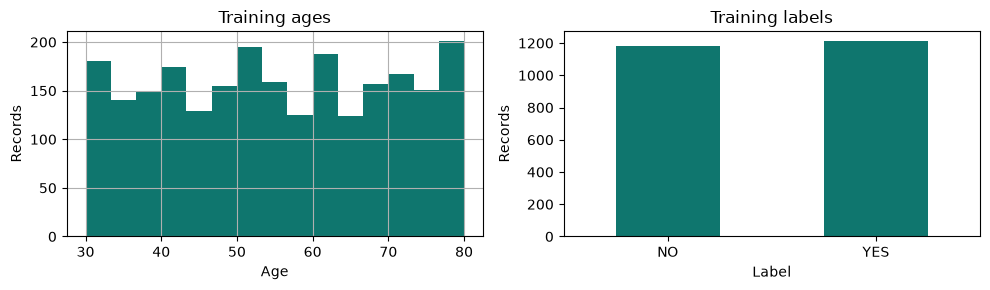

In [10]:
display(X_train.describe().T)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
training["AGE"].hist(bins=15, ax=axes[0], color="#0F766E")
axes[0].set(title="Training ages", xlabel="Age", ylabel="Records")
y_train.map({0: "NO", 1: "YES"}).value_counts().reindex(LABELS).plot.bar(
    ax=axes[1], color="#0F766E", rot=0
)
axes[1].set(title="Training labels", xlabel="Label", ylabel="Records")
plt.tight_layout()
plt.show()
plt.close(fig)

## 7 Define the models

Compare the same five candidate configurations. The highest mean five-fold training macro F1 wins. Model names break ties.

In [11]:
models = {
    "logistic_C0.1": LogisticRegression(
        C=0.1, class_weight="balanced", max_iter=2000, random_state=42),
    "logistic_C1": LogisticRegression(
        C=1.0, class_weight="balanced", max_iter=2000, random_state=42),
    "random_forest_depth6": RandomForestClassifier(
        n_estimators=160, max_depth=6, min_samples_leaf=5,
        class_weight="balanced", n_jobs=1, random_state=42),
    "random_forest_full": RandomForestClassifier(
        n_estimators=160, min_samples_leaf=5,
        class_weight="balanced", n_jobs=1, random_state=42),
    "hist_gradient_boosting": HistGradientBoostingClassifier(
        max_iter=120, max_leaf_nodes=7, learning_rate=0.05,
        l2_regularization=2, class_weight="balanced", random_state=42)
}

In [12]:
if TRAIN_NEW_MODEL:
    if Path(RUN_NAME).name != RUN_NAME or RUN_NAME in ["", ".", ".."]:
        raise ValueError("Use a single folder name for RUN_NAME.")
    run = ARTIFACTS / RUN_NAME
    if run.exists():
        raise ValueError("This run already exists. Choose a new RUN_NAME.")
else:
    run, metadata = resolve_run(ARTIFACTS)
    model, metadata = load_model(run)
    print("Reusing saved model:", metadata["run"])

Reusing saved model: numerical_v1


## 8 Compare models using cross validation

Each candidate is a Pipeline containing a scaler and classifier. The scaler fits only the training portion of each fold. When training is disabled, display the saved CV results.

In [13]:
if TRAIN_NEW_MODEL:
    started = time.perf_counter()
    folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    scoring = {"macro_f1": "f1_macro", "balanced_accuracy": "balanced_accuracy", "roc_auc": "roc_auc"}
    comparison = []

    for name, classifier in models.items():
        pipeline = Pipeline([("scale", StandardScaler()), ("classifier", classifier)])
        scores = cross_validate(
            pipeline, X_train, y_train, cv=folds, scoring=scoring,
            n_jobs=1, error_score="raise"
        )
        row = {"model": name}
        for metric in scoring:
            row[f"cv_{metric}"] = float(scores[f"test_{metric}"].mean())
            row[f"cv_{metric}_std"] = float(scores[f"test_{metric}"].std())
        comparison.append(row)
        print(name, "CV macro F1:", round(row["cv_macro_f1"], 4))

    comparison.sort(key=lambda row: (-row["cv_macro_f1"], row["model"]))
else:
    comparison = metadata["comparison"]

display(pd.DataFrame(comparison).set_index("model").round(4))

,cv_macro_f1,cv_macro_f1_std,cv_balanced_accuracy,cv_balanced_accuracy_std,cv_roc_auc,cv_roc_auc_std
model,,,,,,
hist_gradient_boosting,0.5236,0.0187,0.5242,0.0185,0.5309,0.0146
logistic_C0.1,0.5129,0.0100,0.5131,0.0100,0.5114,0.0158
logistic_C1,0.5125,0.0107,0.5127,0.0108,0.5115,0.0158
random_forest_full,0.5093,0.0030,0.5093,0.0030,0.5194,0.0110
random_forest_depth6,0.5089,0.0049,0.5090,0.0048,0.5215,0.0085


## 9 Fit and save the selected pipeline

Fit the winning model on all training records. Save the scaler and classifier together, then check that reloading produces the same scores.

In [14]:
if TRAIN_NEW_MODEL:
    winner = comparison[0]["model"]
    model = Pipeline([
        ("scale", StandardScaler()),
        ("classifier", models[winner])
    ])
    model.fit(X_train, y_train)

    run.mkdir(parents=True)
    joblib.dump(model, run / "model.joblib", compress=3)
    reloaded = joblib.load(run / "model.joblib")
    if not np.allclose(model.predict_proba(X_train.head()), reloaded.predict_proba(X_train.head())):
        raise ValueError("Predictions changed after reloading the saved model.")
    print("Saved model:", run / "model.joblib")

## 10 Calculate evaluation metrics

This small helper avoids repeating the same calculations for the selected model and baseline. It returns accuracy, a Wilson confidence interval, balanced accuracy, macro F1, ROC AUC, a confusion matrix and class-wise scores. YES is the positive class.

In [15]:
def calculate_metrics(truth, predicted, scores):
    accuracy = float(accuracy_score(truth, predicted))
    n, z = len(truth), 1.95996398454
    denominator = 1 + z*z/n
    centre = (accuracy + z*z/(2*n))/denominator
    radius = z*math.sqrt(accuracy*(1-accuracy)/n + z*z/(4*n*n))/denominator
    return {"records": n, "accuracy": accuracy,
            "accuracy_wilson_95": [centre-radius, centre+radius],
            "balanced_accuracy": float(balanced_accuracy_score(truth, predicted)),
            "macro_f1": float(f1_score(truth, predicted, average="macro", zero_division=0)),
            "roc_auc": float(roc_auc_score(truth, scores)),
            "confusion_matrix": confusion_matrix(truth, predicted, labels=[0, 1]).tolist(),
            "per_class": classification_report(truth, predicted, labels=[0, 1], target_names=list(LABELS),
                                                output_dict=True, zero_division=0)}

## 11 Evaluate a new model only when no frozen test report exists

The first selected model uses the reserved test records once. Later training runs preserve that report and receive CV-only metadata. Do not attach the original test scores to a different model.

In [16]:
test_metrics = None
test_report = REPORTS / "test_evaluation.json"

if TRAIN_NEW_MODEL and not test_report.exists():
    X_test = testing.loc[:, list(FEATURES)]
    y_test = testing[TARGET]
    scores = model.predict_proba(X_test)[:, 1]
    predictions = (scores >= 0.5).astype(int)
    test_metrics = calculate_metrics(y_test, predictions, scores)

    baseline_model = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
    baseline = calculate_metrics(
        y_test, baseline_model.predict(X_test), baseline_model.predict_proba(X_test)[:, 1]
    )
    test_metrics.update({
        "model": winner, "run": RUN_NAME, "split_id": summary["split_id"],
        "threshold": 0.5, "baseline": baseline,
        "evaluation": "single fixed held-out row-level test"
    })
    write_json(test_report, test_metrics)

    prediction_table = testing[["row_id", TARGET]].copy()
    prediction_table["predicted_label"] = [LABELS[value] for value in predictions]
    prediction_table["yes_model_score"] = scores
    prediction_table.to_csv(run / "test_predictions.csv", index=False)

## 12 Save metadata for the app

Keep the existing file format so the Streamlit application can use the new model without UI changes. This cell writes only when training is enabled.

In [17]:
if TRAIN_NEW_MODEL:
    quality_note = "Exploratory dataset-label classification; clinical performance is unverified."
    if comparison[0]["cv_balanced_accuracy"] < 0.60:
        quality_note = "Performance is near chance. This dataset/model has not demonstrated reliable predictive skill."
    if test_metrics and test_metrics["balanced_accuracy"] < 0.60:
        quality_note = "Performance is near chance. This dataset/model has not demonstrated reliable predictive skill."

    metadata = {
        "schema_version": SCHEMA_VERSION, "model": winner, "run": RUN_NAME,
        "features": list(FEATURES), "labels": list(LABELS),
        "age_range": summary["age_range"], "split_id": summary["split_id"],
        "csv_sha256": summary["csv_sha256"], "model_sha256": sha256(run / "model.joblib"),
        "sklearn_version": sklearn.__version__, "training_records": len(training),
        "cv_folds": 5, "selection_metric": "five-fold training-only macro F1; name breaks ties",
        "comparison": comparison, "training_seconds": time.perf_counter() - started,
        "created_utc": datetime.now(timezone.utc).isoformat(), "device": "CPU",
        "test_metrics": test_metrics,
        "classifier_parameters": model.named_steps["classifier"].get_params(),
        "quality_note": quality_note,
        "evaluation_note": "Held-out test evaluated after CV selection." if test_metrics else
            "CV only: this dataset's test split was previously viewed; no fresh independent test score."
    }
    write_json(run / "metadata.json", metadata)
    pd.DataFrame(comparison).to_csv(run / "cv_comparison.csv", index=False)
    write_json(ARTIFACTS / "active.json", {
        "run": RUN_NAME, "model_sha256": metadata["model_sha256"],
        "split_id": metadata["split_id"], "schema_version": SCHEMA_VERSION
    })
    print("Active model:", RUN_NAME)

## 13 View the original held out results

Display the original evaluated run and majority-label baseline. These results belong only to the named evaluated run, even if another run is now active. Displaying saved evidence does not retrain or overwrite it.

In [18]:
evaluation = read_json(test_report)
if evaluation["split_id"] != summary["split_id"]:
    raise ValueError("The saved evaluation belongs to another data split.")

print("Evaluated run:", evaluation["run"])
print("Active run:", metadata["run"])
rows = []
for name, result in [(evaluation["model"], evaluation), ("Majority baseline", evaluation["baseline"])]:
    positive = result["per_class"]["YES"]
    rows.append({
        "Model": name, "Accuracy": result["accuracy"],
        "Precision": positive["precision"], "Recall": positive["recall"],
        "F1": positive["f1-score"], "Macro F1": result["macro_f1"], "ROC AUC": result["roc_auc"]
    })
display(pd.DataFrame(rows).set_index("Model").round(4))
print("95% Wilson accuracy interval:", evaluation["accuracy_wilson_95"])

Evaluated run: numerical_v1
Active run: numerical_v1


,Accuracy,Precision,Recall,F1,Macro F1,ROC AUC
Model,,,,,,
hist_gradient_boosting,0.5092,0.5170,0.4521,0.4824,0.5079,0.5309
Majority baseline,0.5058,0.5058,1.0000,0.6718,0.3359,0.5000


95% Wilson accuracy interval: [0.4692169486578002, 0.549029971554885]


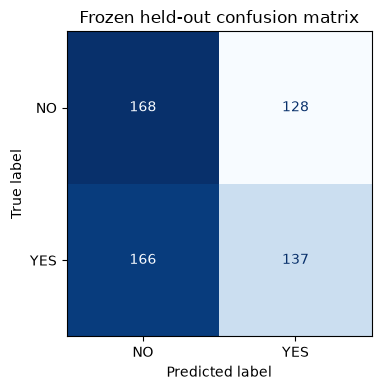

In [19]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(
    np.array(evaluation["confusion_matrix"]), display_labels=list(LABELS)
).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Frozen held-out confusion matrix")
plt.tight_layout()
plt.show()
plt.close(fig)

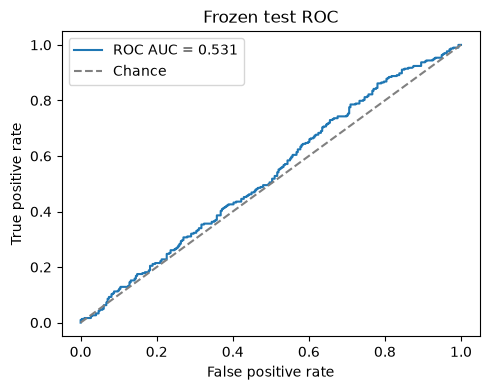

In [20]:
prediction_file = ARTIFACTS / evaluation["run"] / "test_predictions.csv"
if prediction_file.exists():
    saved_predictions = pd.read_csv(prediction_file)
    expected = testing.set_index("row_id")[TARGET]
    if saved_predictions["row_id"].duplicated().any() or set(saved_predictions["row_id"]) != set(expected.index):
        raise ValueError("Saved predictions do not match the fixed test records.")
    if not np.array_equal(saved_predictions[TARGET], expected.loc[saved_predictions["row_id"]].to_numpy()):
        raise ValueError("Saved test labels do not match the fixed test records.")
    fpr, tpr, _ = roc_curve(saved_predictions[TARGET], saved_predictions["yes_model_score"])
    fig, ax = plt.subplots(figsize=(5, 4))
    ax.plot(fpr, tpr, label=f"ROC AUC = {evaluation['roc_auc']:.3f}")
    ax.plot([0, 1], [0, 1], "--", color="gray", label="Chance")
    ax.set(xlabel="False positive rate", ylabel="True positive rate", title="Frozen test ROC")
    ax.legend()
    plt.tight_layout()
    plt.show()
    plt.close(fig)

## 14 Training only feature analysis

This optional calculation uses up to 512 training records and five shuffles. It measures in-sample model reliance, not clinical importance, causality or external validation. Existing diagnostics are displayed without changes unless regeneration is enabled.

In [21]:
if REGENERATE_DIAGNOSTICS:
    if summary["split_id"] != metadata["split_id"]:
        raise ValueError("The diagnostic data does not match the model split.")
    sample = training.sample(n=min(512, len(training)), random_state=42)
    X_sample = sample.loc[:, list(FEATURES)]
    y_sample = sample[TARGET]
    importance = permutation_importance(
        model, X_sample, y_sample, scoring="balanced_accuracy",
        n_repeats=5, random_state=42, n_jobs=1
    )
    feature_scores = []
    for name, mean, std in zip(FEATURES, importance.importances_mean, importance.importances_std):
        feature_scores.append({"feature": name, "importance": float(mean), "std": float(std)})
    diagnostics = {
        "model_sha256": metadata["model_sha256"], "split_id": metadata["split_id"],
        "run": metadata["run"], "partition": "training only", "records": len(sample),
        "repeats": 5, "seed": 42, "scoring": "balanced accuracy",
        "training_subset_score": float(balanced_accuracy_score(y_sample, model.predict(X_sample))),
        "features": feature_scores,
        "limitation": "In-sample training reliance, not clinical relevance or external validation."
    }
    write_json(REPORTS / "feature_importance.json", diagnostics)

In [22]:
diagnostics_file = REPORTS / "feature_importance.json"
if diagnostics_file.exists():
    diagnostics = read_json(diagnostics_file)
    print("Diagnostic run:", diagnostics["run"])
    if diagnostics["model_sha256"] != metadata["model_sha256"]:
        print("These saved diagnostics belong to a different model, not the active run.")
    display(pd.DataFrame(diagnostics["features"]).sort_values("importance", ascending=False))

Diagnostic run: numerical_v1


,feature,importance,std
0,AGE,0.093845,0.022838
11,COUGHING,0.026189,0.012652
9,WHEEZING,0.019571,0.009988
7,FATIGUE,0.014570,0.009720
14,CHEST_PAIN,0.012189,0.005471
8,ALLERGY,0.010222,0.005013
5,PEER_PRESSURE,0.010213,0.005184
12,SHORTNESS_OF_BREATH,0.008990,0.003147
2,SMOKING,0.008963,0.006502
10,ALCOHOL_CONSUMING,0.007601,0.010810


## 15 Use the model in the application

The notebook saves `model.joblib`, `metadata.json`, `cv_comparison.csv` and the active-model pointer. The app uses these files directly.

- `app.py`: page setup, cached model loading, sidebar and navigation.
- `ui_pages/`: opens each screen.
- `lung_tabular/ui.py`: forms, uploads, prediction results and saved evaluation displays.
- `lung_tabular/data.py`: shared input validation and prepared-file integrity checks.
- `lung_tabular/model.py`: model loading and prediction.
- `lung_tabular/evaluation.py`: formats saved metrics for the dashboard.

The small terminal runner uses Jupyter to execute this notebook when an offline command is requested. It does not load hidden code definitions or run during application prediction.

In [23]:
example = X_train.head(2)
display(predict_records(example, model, metadata))
print("Start the app with run.ps1")

,AGE,GENDER,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC_DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL_CONSUMING,COUGHING,SHORTNESS_OF_BREATH,SWALLOWING_DIFFICULTY,CHEST_PAIN,predicted_dataset_label,no_model_score,yes_model_score,model_run,model_sha256
0,53,1,1,1,0,0,0,1,0,0,0,1,1,1,1,YES,0.466741,0.533259,numerical_v1,b03b0498c128de3028234b7fbbed9abe227f0e2e26de97...
1,35,0,1,1,1,1,0,1,1,1,0,0,0,0,1,YES,0.366857,0.633143,numerical_v1,b03b0498c128de3028234b7fbbed9abe227f0e2e26de97...


Start the app with run.ps1
